# 02 - Simple Linear Regression with scikit-learn

## Aim
Build a simple linear regression model with `scikit-learn`, make predictions, calculate common performance measures, and visualize the fitted line.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load and inspect the data

In [2]:
df = pd.read_csv("datasets/P176.txt", sep="\t")
display(df.head())
print("Shape:", df.shape)

,X,Y
0,294,30
1,247,32
2,267,37
3,358,44
4,423,47


Shape: (27, 2)


## 3. Prepare the feature matrix and target vector
`scikit-learn` expects the input feature matrix to be two-dimensional.

In [3]:
X = df[["X"]]
y = df["Y"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (27, 1)
Target shape: (27,)


## 4. Create and train the model

In [4]:
model = LinearRegression()
model.fit(X, y)

print(f"Coefficient: {model.coef_[0]:.6f}")
print(f"Intercept : {model.intercept_:.6f}")

Coefficient: 0.105361
Intercept : 14.448059


## 5. Predict the training observations

In [5]:
y_hat = model.predict(X)

results = pd.DataFrame({
    "Actual": y,
    "Predicted": y_hat
})
results.head(10)

,Actual,Predicted
0,30,45.424220
1,32,40.472249
2,37,42.579471
3,44,52.167330
4,47,59.015801
5,49,47.215359
6,56,61.860551
7,62,70.710883
8,68,60.596218
9,78,87.884741


## 6. Predict unseen values

In [6]:
new_x = pd.DataFrame({"X": [250, 1200, 1400]})
new_predictions = model.predict(new_x)

for value, estimate in zip(new_x["X"], new_predictions):
    print(f"X = {value:4.0f}  ->  predicted Y = {estimate:.2f}")

X =  250  ->  predicted Y = 40.79
X = 1200  ->  predicted Y = 140.88
X = 1400  ->  predicted Y = 161.95


## 7. Evaluate the model

In [7]:
mse = mean_squared_error(y, y_hat)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y, y_hat)
r2 = r2_score(y, y_hat)

print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MAE  : 16.1397
MSE  : 437.1876
RMSE : 20.9090
R²   : 0.7759


## 8. Visualize the fitted model

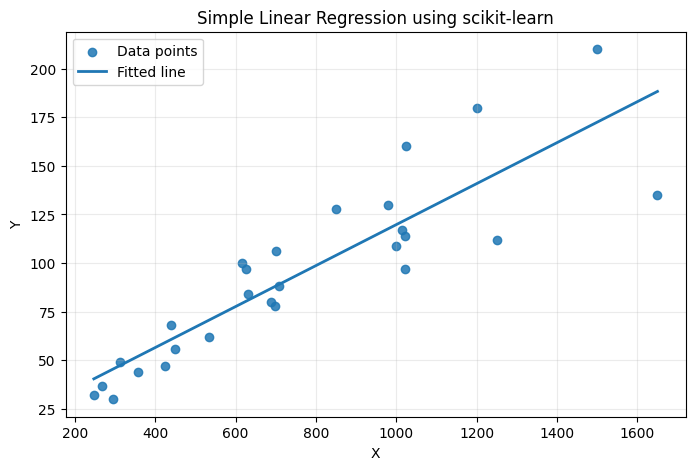

In [8]:
sorted_order = np.argsort(X["X"].to_numpy())

plt.figure(figsize=(8, 5))
plt.scatter(X["X"], y, alpha=0.85, label="Data points")
plt.plot(
    X["X"].to_numpy()[sorted_order],
    y_hat[sorted_order],
    linewidth=2,
    label="Fitted line"
)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Simple Linear Regression using scikit-learn")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Conclusion
`LinearRegression` estimates the same straight-line relationship as the least-squares calculation, while also providing convenient prediction and model-evaluation methods.